# v2 - Conditional beta

Robert Miller

v1 showed that a trend filter on SPY by itself cuts drawdowns but gives up too much return. For v2 I wanted to see if I could use beta instead of just turning it off, specifically by holding more of it when the market is going up and less when it isn't. Same goal as before: more money after taxes than buy and hold SPY in a regular brokerage account, checked once a month.

### Background

The idea mostly comes from Lakonishok and Shapiro (1984). Across NYSE stocks from 1962-1980, beta by itself didn't explain returns, but high beta stocks did better than low beta stocks in up markets and worse in down markets. Pettengill, Sundaram and Mathur (1995) built a test around that, and both Xiao (2016, US) and Elsas, El-Shaer and Theissen (2003, Germany) found the same thing with it. Beta only seems to pay if you know which way the market is going.

The catch is that their test splits months by the market's return in that same month, which you can't know ahead of time. The question for this notebook is whether a trend signal you do know ahead of time can stand in for it.

A few other papers shaped the setup:
- Zenner et al. (2008) put the market risk premium at about 5-7% a year, so sitting in cash has a real cost.
- Genc, Moench and Pazarbasi (2025) found fund managers pile into high beta stocks when rates rise, which raises raw returns but not risk-adjusted ones, so high beta can be a crowded trade.
- Hsu, Kalesnik and Li (2012) found equal weighting beat the S&P 500 from 1967-2010, mostly through value and small-cap tilts (which Campbell and Vuolteenaho's "bad beta" paper helps explain). I include an equal weight sector portfolio as a comparison for that reason.

### Rules

On the last trading day of each month, the trend is "up" if SPY's total return index is above its 8, 10 or 12 month average. In an uptrend the strategy takes on more beta, either by holding 100% SPY, the 2-4 highest beta sector ETFs (with beta measured over the last 6 or 12 months), or a SPY/SSO mix that gets to a beta of 1.5 or 2. In a downtrend it takes on less, so it either moves to T-bills or holds the 3 lowest beta sectors. There's also an option to shrink the uptrend position when SPY's volatility over the last month is above 20%. Like v1, nothing trades unless a holding is at least 5% off its target.

### Fees and taxes

$10,000 start, $0 commission, 5 bps spread/slippage, and expense ratios are already in the prices. Cash is SGOV (T-bill rate minus 0.09%). Federal tax only: 22% on short-term gains, T-bill interest and SSO payouts, 15% on long-term gains and dividends. Tax lots are FIFO, losses carry forward, and the wash sale rule is applied. I don't credit the $3,000 deduction against other income, since that saving happens outside the account (`use_loss_deduction` turns it on).

Trades go in at the next day's close after the signal. My first version traded at the same close the signal came from, which isn't actually possible and made everything look a little better.

Data is from Yahoo Finance (Adj Close, so dividends are in) and FRED (3-month T-bill rate, DTB3). Run `python get_data.py` first.

### What this notebook reproduces

This is the full analysis behind v2 in the README. Section 3 here is the conditional beta test in README Section 5.4, Section 4 uses the grid in the v2 row of README Table 2, Section 5 gives the v2 row of README Table 3, and Section 7 gives the 2005 walk-forward numbers under that table. It reads SPY, SSO, the nine sector ETFs and the T-bill rate from the `data/` folder, so run `python get_data.py` from the main folder first, and then run every cell from top to bottom. The last cell prints the package versions and data files it was run with.

In [1]:
import math
import itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import strategy
from strategy import (load_data, get_target_weights, get_sector_betas, simulate, run_strategy,
                      run_fixed, get_stats, after_tax_cagr, block_bootstrap, get_month_ends,
                      get_settings_grid, walk_forward, chosen_settings, start_value, sectors,
                      tickers, trading_days)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 200)

data = load_data()
returns = data["total_return"]

print("First date:", data["dates"][0].date())
print("Last date:", data["dates"][-1].date())
for ticker in tickers:
    print(ticker, "starts", returns[ticker].first_valid_index().date())

First date: 1993-01-29
Last date: 2026-10-29
SPY starts 1993-02-01
SSO starts 1993-02-01
XLB starts 1998-12-23
XLE starts 1998-12-23
XLF starts 1998-12-23
XLI starts 1998-12-23
XLK starts 1998-12-23
XLP starts 1998-12-23
XLU starts 1998-12-23
XLV starts 1998-12-23
XLY starts 1998-12-23


## 1. Checking the rebuilt SSO

SSO only exists since June 2006, but training starts in 2000, so before that I rebuild it from SPY: 2x SPY's daily return, minus the T-bill rate plus a spread on the borrowed half, minus SSO's 0.89% fee. I set the spread so the rebuilt version grows at the same rate as the real one over the years where both exist.

Real SSO CAGR since 2006-06-21 : 15.68%
Best matching borrowing spread: 0.7%
Spread saved in strategy.py: 0.7%
Correlation of daily returns: 0.9956
Tracking error per year: 3.64%


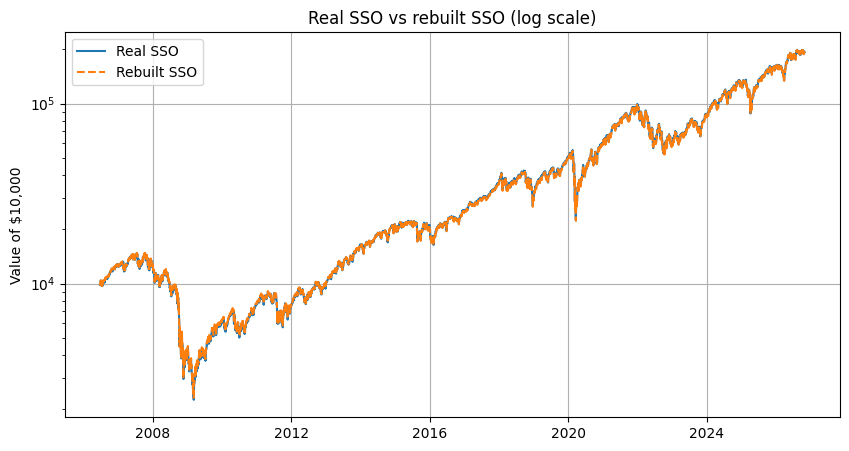

In [2]:
overlap = returns.index > data["first_sso"]
real_sso = returns.loc[overlap, "SSO_actual"]
spy_part = 2 * returns.loc[overlap, "SPY"] - data["tbill_return"][overlap]
years_overlap = overlap.sum() / trading_days

def rebuilt_cagr(spread):
    rebuilt = spy_part - (spread + strategy.sso_fee) / trading_days
    return (1 + rebuilt).prod() ** (1 / years_overlap) - 1

real_cagr = (1 + real_sso).prod() ** (1 / years_overlap) - 1

# brute force the spread
spreads = np.arange(0, 0.0201, 0.0005)
gaps = [abs(rebuilt_cagr(x) - real_cagr) for x in spreads]
best_spread = spreads[int(np.argmin(gaps))]

print("Real SSO CAGR since", data["first_sso"].date(), ":", str(round(real_cagr * 100, 2)) + "%")
print("Best matching borrowing spread:", str(round(best_spread * 100, 2)) + "%")
print("Spread saved in strategy.py:", str(round(strategy.sso_spread * 100, 2)) + "%")
if abs(best_spread - strategy.sso_spread) > 0.00049:
    print("These do not match. Update sso_spread in strategy.py.")

rebuilt = spy_part - (strategy.sso_spread + strategy.sso_fee) / trading_days
print("Correlation of daily returns:", round(rebuilt.corr(real_sso), 4))
print("Tracking error per year:", str(round((rebuilt - real_sso).std() * math.sqrt(trading_days) * 100, 2)) + "%")

plt.figure(figsize=(10,5))
plt.plot(real_sso.index, (1 + real_sso).cumprod() * 10000, label="Real SSO")
plt.plot(rebuilt.index, (1 + rebuilt).cumprod() * 10000, label="Rebuilt SSO", linestyle="--")
plt.yscale("log")
plt.title("Real SSO vs rebuilt SSO (log scale)")
plt.ylabel("Value of $10,000")
plt.legend()
plt.grid(True)
plt.show()

## 2. Train / test split

Settings get picked on 2000-2009 only. I don't look at 2010 on until they're locked in.

In [3]:
train_start = "2000-01-01"
train_end = "2009-12-31"
test_start = "2010-01-01"

print("Training:", train_start, "to", train_end)
print("Testing:", test_start, "to", data["dates"][-1].date())

Training: 2000-01-01 to 2009-12-31
Testing: 2010-01-01 to 2026-10-29


## 3. Does conditional beta work on sector ETFs?

Each month I regress the sectors' next-month returns (over T-bills) on their beta from the previous 12 months, then average the slopes three ways:

1. Split by whether SPY beat T-bills *that next month*. This is the Pettengill et al. (1995) test, but it isn't tradable since it uses next month's return. Furthermore, the sign of the result is mostly automatic. If betas stay about the same from year to year, high beta sectors will move more than low beta ones in whichever direction the market goes, so this test mostly shows that betas are stable.
2. Split by the trend signal at the *start* of the month (SPY above/below its 10-month average). This one is tradable, and it's the one the strategy can use.
3. All months, no split.

This is the test behind README Section 5.4.

In [4]:
def conditional_beta_test(start, end, beta_window=252):

    betas = get_sector_betas(data, beta_window)
    month_ends = get_month_ends(data["dates"])
    month_ends = month_ends[(month_ends >= pd.Timestamp(start) - pd.Timedelta(days=40)) & (month_ends <= pd.Timestamp(end))]

    growth = (1 + returns[sectors + ["SPY"]].fillna(0)).cumprod()
    tbill_growth = (1 + data["tbill_return"]).cumprod()

    rows = []
    for i in range(len(month_ends) - 1):
        now = month_ends[i]
        later = month_ends[i + 1]

        beta_now = betas.loc[now, sectors]
        if beta_now.isna().any():
            continue

        tbill = tbill_growth.loc[later] / tbill_growth.loc[now] - 1
        next_return = growth.loc[later, sectors] / growth.loc[now, sectors] - 1 - tbill
        market = growth.loc[later, "SPY"] / growth.loc[now, "SPY"] - 1 - tbill

        slope = np.polyfit(beta_now.values, next_return.values, 1)[0]
        rows.append({"date": later, "slope": slope, "market_up": market > 0,
                     "trend_up": bool(trend_up.loc[now])})

    return pd.DataFrame(rows)


# trend signal known at each month end (10 month SMA)
spy_growth = (1 + returns["SPY"].fillna(0)).cumprod()
monthly_spy = spy_growth.loc[get_month_ends(data["dates"])]
trend_up = monthly_spy > monthly_spy.rolling(10).mean()

for name, start, end in [("Training (2000-2009)", train_start, train_end),
                         ("Testing (2010-now)", test_start, str(data["dates"][-1].date()))]:

    test = conditional_beta_test(start, end)
    print(name)
    for label, group in [("All months (tradable)", test),
                         ("Trend up at the start of the month (tradable)", test[test["trend_up"]]),
                         ("Trend down at the start of the month (tradable)", test[~test["trend_up"]]),
                         ("SPY beat T-bills next month (NOT tradable)", test[test["market_up"]]),
                         ("SPY lost to T-bills next month (NOT tradable)", test[~test["market_up"]])]:
        mean = group["slope"].mean()
        t_stat = mean / (group["slope"].std() / math.sqrt(len(group)))
        print("  " + label + ":", len(group), "months, average slope", str(round(mean * 100, 2)) + "%",
              "per 1.0 of beta, t =", round(t_stat, 2))
    print()

Training (2000-2009)
  All months (tradable): 120 months, average slope -0.39% per 1.0 of beta, t = -0.55
  Trend up at the start of the month (tradable): 71 months, average slope -0.16% per 1.0 of beta, t = -0.21
  Trend down at the start of the month (tradable): 49 months, average slope -0.72% per 1.0 of beta, t = -0.55
  SPY beat T-bills next month (NOT tradable): 64 months, average slope 3.08% per 1.0 of beta, t = 3.47
  SPY lost to T-bills next month (NOT tradable): 56 months, average slope -4.35% per 1.0 of beta, t = -5.24

Testing (2010-now)
  All months (tradable): 203 months, average slope 0.4% per 1.0 of beta, t = 0.7
  Trend up at the start of the month (tradable): 172 months, average slope 0.03% per 1.0 of beta, t = 0.06
  Trend down at the start of the month (tradable): 31 months, average slope 2.45% per 1.0 of beta, t = 1.26
  SPY beat T-bills next month (NOT tradable): 135 months, average slope 2.65% per 1.0 of beta, t = 3.88
  SPY lost to T-bills next month (NOT tradabl

## 4. Picking settings on 2000-2009

Every combination run with taxes, ranked by after-tax CAGR (selling everything at the end of 2009), which is the same definition of winning I use in the test.

The grid here is the v2 row of Table 2 in the README.

In [5]:
settings_list = get_settings_grid()

results = []

for settings in settings_list:

    bt = run_strategy(data, settings, start=train_start, end=train_end, taxes=True)
    stats = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])

    row = dict(settings)
    row["after_tax_cagr"] = after_tax_cagr(bt)
    row["sharpe"] = stats["sharpe"]
    row["max_drawdown"] = stats["max_drawdown"]
    row["beta"] = stats["beta"]
    results.append(row)

train_results = pd.DataFrame(results).sort_values("after_tax_cagr", ascending=False)

hold_train = run_fixed(data, {"SPY": 1.0}, start=train_start, end=train_end, taxes=True)
print("Combinations tested:", len(train_results))
print("Buy and hold SPY after-tax CAGR in training:", str(round(after_tax_cagr(hold_train) * 100, 2)) + "%")
train_results.head(10)

Combinations tested: 126
Buy and hold SPY after-tax CAGR in training: -1.18%


,sma_months,up_mode,up_size,down_mode,beta_window,target_vol,after_tax_cagr,sharpe,max_drawdown,beta
79,10,leverage,2.000,cash,252,0.200,0.090,0.419,-0.262,0.468
121,12,leverage,2.000,cash,252,0.200,0.087,0.395,-0.259,0.472
78,10,leverage,2.000,cash,252,NaN,0.086,0.395,-0.260,0.498
120,12,leverage,2.000,cash,252,NaN,0.083,0.370,-0.289,0.501
48,10,sectors,2.000,cash,126,NaN,0.081,0.426,-0.176,0.298
49,10,sectors,2.000,cash,126,0.200,0.080,0.432,-0.179,0.281
90,12,sectors,2.000,cash,126,NaN,0.080,0.403,-0.191,0.303
73,10,leverage,1.500,cash,252,0.200,0.079,0.424,-0.194,0.354
91,12,sectors,2.000,cash,126,0.200,0.078,0.407,-0.193,0.287
115,12,leverage,1.500,cash,252,0.200,0.076,0.395,-0.187,0.355


In [6]:
best = train_results.iloc[0]

best_settings = {
    "sma_months": int(best["sma_months"]),
    "up_mode": best["up_mode"],
    "up_size": float(best["up_size"]) if best["up_mode"] == "leverage" else int(best["up_size"]),
    "down_mode": best["down_mode"],
    "beta_window": int(best["beta_window"]),
    "target_vol": None if pd.isna(best["target_vol"]) else float(best["target_vol"]),
}

print("Best settings on training data:", best_settings)
print("Settings saved in strategy.py:", chosen_settings)

if best_settings != chosen_settings:
    print("These do not match. Update chosen_settings in strategy.py so monthly_signal.py uses them.")

# which uptrend position did best on average?
print()
print(train_results.groupby("up_mode")["after_tax_cagr"].agg(["mean", "max"]))

Best settings on training data: {'sma_months': 10, 'up_mode': 'leverage', 'up_size': 2.0, 'down_mode': 'cash', 'beta_window': 252, 'target_vol': 0.2}
Settings saved in strategy.py: {'sma_months': 10, 'up_mode': 'leverage', 'up_size': 2.0, 'down_mode': 'cash', 'beta_window': 252, 'target_vol': 0.2}

          mean   max
up_mode             
leverage 0.040 0.090
sectors  0.039 0.081
spy      0.024 0.065


## 5. Testing on 2010 to now

Compared to:
- buy and hold SPY (the benchmark)
- buy and hold SSO, to see if the trend filter adds anything or if it's just the leverage
- trend + SPY only, which is close to v1 without the vol targeting
- equal weight sectors, as a simple smart beta comparison (Hsu et al. 2012)

The signals warm up on data before 2010, but returns only count from 2010 on.

The after-tax results in this section are the v2 row of Table 3 in the README.

In [7]:
s = best_settings

trend_spy = dict(s)
trend_spy["up_mode"] = "spy"
trend_spy["up_size"] = 1
trend_spy["down_mode"] = "cash"
trend_spy["target_vol"] = None

equal_sectors = {sector: 1 / len(sectors) for sector in sectors}

runs = {
    "Strategy": lambda tax: run_strategy(data, s, start=test_start, taxes=tax),
    "Buy and hold SPY": lambda tax: run_fixed(data, {"SPY": 1.0}, start=test_start, taxes=tax),
    "Buy and hold SSO": lambda tax: run_fixed(data, {"SSO": 1.0}, start=test_start, taxes=tax),
    "Trend + SPY": lambda tax: run_strategy(data, trend_spy, start=test_start, taxes=tax),
    "Equal weight sectors": lambda tax: run_fixed(data, equal_sectors, start=test_start, taxes=tax),
}

pre_tax = {name: run(False) for name, run in runs.items()}
with_tax = {name: run(True) for name, run in runs.items()}

table = {}
for name in runs:
    bt = pre_tax[name]
    taxed = with_tax[name]
    stats = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])
    table[name] = {
        "value_before_tax": bt["value"].iloc[-1],
        "value_after_tax_sold": taxed.attrs["liquidation_value"],
        "taxes_paid_along_the_way": taxed.attrs["total_taxes"],
        "cagr_before_tax": stats["cagr"],
        "cagr_after_tax": after_tax_cagr(taxed),
        "volatility": stats["volatility"],
        "sharpe": stats["sharpe"],
        "max_drawdown": stats["max_drawdown"],
        "beta": stats["beta"],
    }

table = pd.DataFrame(table)

strategy_test = with_tax["Strategy"]
hold_test = with_tax["Buy and hold SPY"]

years = len(strategy_test) / trading_days
turnover = (strategy_test["traded"] / strategy_test["value"]).sum() / years

print("Trades:", int((strategy_test["traded"] > 0).sum()), "rebalances in", round(years, 1), "years")
print("Average turnover per year:", str(round(turnover * 100)) + "% of the account")
print("Total trading costs: $" + format(round(strategy_test["cost"].sum(), 2), ","))
print()
win = table.loc["value_after_tax_sold", "Strategy"] > table.loc["value_after_tax_sold", "Buy and hold SPY"]
print("Strategy beat buy and hold SPY after taxes:", win)
table

Trades: 44 rebalances in 16.8 years
Average turnover per year: 235% of the account
Total trading costs: $440.93

Strategy beat buy and hold SPY after taxes: False


,Strategy,Buy and hold SPY,Buy and hold SSO,Trend + SPY,Equal weight sectors
value_before_tax,"64,159.596","91,144.331","311,165.088","34,773.193","77,920.921"
value_after_tax_sold,"48,695.916","76,769.447","261,801.029","28,779.605","64,982.985"
taxes_paid_along_the_way,"5,437.747","1,311.548","1,538.904","2,749.013","2,129.627"
cagr_before_tax,0.117,0.141,0.227,0.077,0.130
cagr_after_tax,0.099,0.129,0.215,0.065,0.118
volatility,0.254,0.170,0.340,0.130,0.163
sharpe,0.506,0.772,0.730,0.523,0.742
max_drawdown,-0.448,-0.337,-0.593,-0.263,-0.357
beta,1.135,0.999,1.997,0.582,0.924


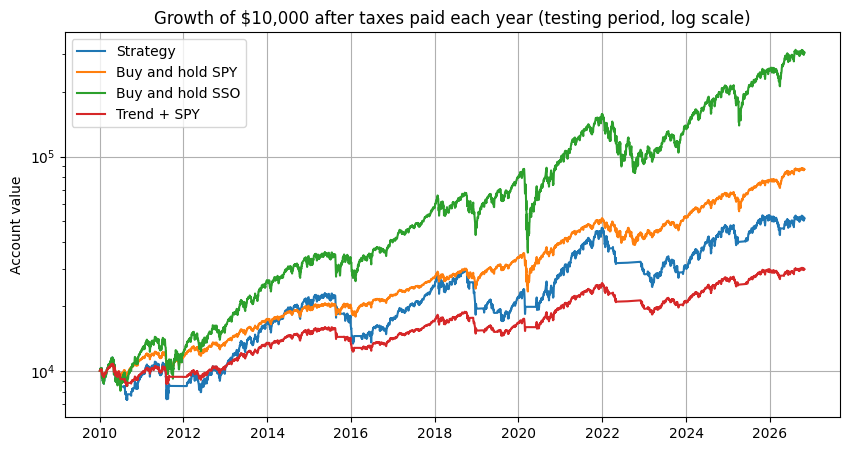

In [8]:
plt.figure(figsize=(10,5))
for name in ["Strategy", "Buy and hold SPY", "Buy and hold SSO", "Trend + SPY"]:
    plt.plot(with_tax[name].index, with_tax[name]["value"], label=name)
plt.yscale("log")
plt.title("Growth of $10,000 after taxes paid each year (testing period, log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.show()

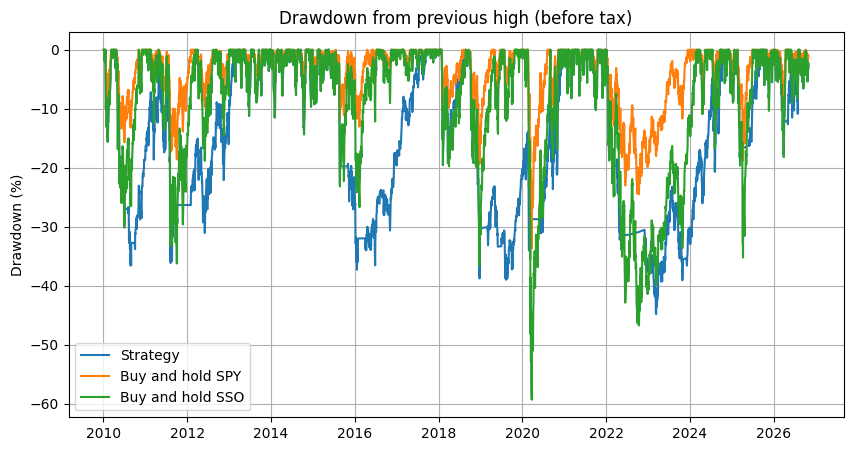

In [9]:
def drawdown_series(returns):
    growth = (1 + returns).cumprod()
    return growth / growth.cummax() - 1

plt.figure(figsize=(10,5))
for name in ["Strategy", "Buy and hold SPY", "Buy and hold SSO"]:
    plt.plot(pre_tax[name].index, drawdown_series(pre_tax[name]["strategy_return"]) * 100, label=name)
plt.title("Drawdown from previous high (before tax)")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(True)
plt.show()

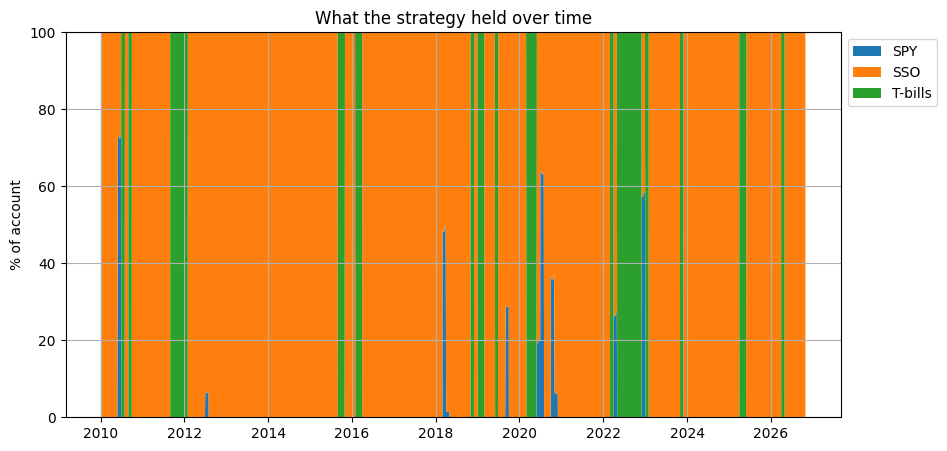

Average % of the account in each holding:
SPY        1.900
SSO       82.800
T-bills   15.400
dtype: float64


In [10]:
# what the strategy held over time
weight_columns = ["w_" + ticker for ticker in tickers]
held = pre_tax["Strategy"][weight_columns].copy()
held.columns = tickers
held = held.loc[:, held.max() > 0.001]
held["T-bills"] = 1 - held.sum(axis=1)

plt.figure(figsize=(10,5))
plt.stackplot(held.index, [held[c] * 100 for c in held.columns], labels=held.columns)
plt.title("What the strategy held over time")
plt.ylabel("% of account")
plt.ylim(0, 100)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.grid(True)
plt.show()

print("Average % of the account in each holding:")
print((held.mean() * 100).round(1))

In [11]:
# calendar year returns (before tax)
strategy_pre = pre_tax["Strategy"]
hold_pre = pre_tax["Buy and hold SPY"]

yearly = pd.DataFrame({
    "Strategy": (1 + strategy_pre["strategy_return"]).groupby(strategy_pre.index.year).prod() - 1,
    "Buy and hold SPY": (1 + hold_pre["strategy_return"]).groupby(hold_pre.index.year).prod() - 1,
})
yearly["Difference"] = yearly["Strategy"] - yearly["Buy and hold SPY"]
yearly = yearly.loc[yearly.index >= 2010]

print("Years the strategy beat buy and hold:", int((yearly["Difference"] > 0).sum()), "out of", len(yearly))
yearly

Years the strategy beat buy and hold: 7 out of 17


,Strategy,Buy and hold SPY,Difference
Date,,,
2010,-0.060,0.131,-0.190
2011,-0.095,0.019,-0.114
2012,0.180,0.160,0.020
2013,0.705,0.323,0.382
2014,0.255,0.135,0.121
2015,-0.183,0.012,-0.196
2016,0.060,0.120,-0.060
2017,0.444,0.217,0.226
2018,-0.160,-0.046,-0.114


## 6. Was the pick just lucky?

If only the one setting I picked beats buy and hold, it's probably overfit, so this runs every combination on the test years (with taxes).

Settings that beat buy and hold SPY after taxes: 22 out of 126

By up trend position:
                  count  mean   min   max
up_mode  up_size                         
leverage 1.500       18 0.122 0.082 0.142
         2.000       18 0.143 0.094 0.168
sectors  2.000       24 0.085 0.050 0.111
         3.000       24 0.080 0.046 0.107
         4.000       24 0.081 0.051 0.105
spy      1.000       18 0.098 0.065 0.114


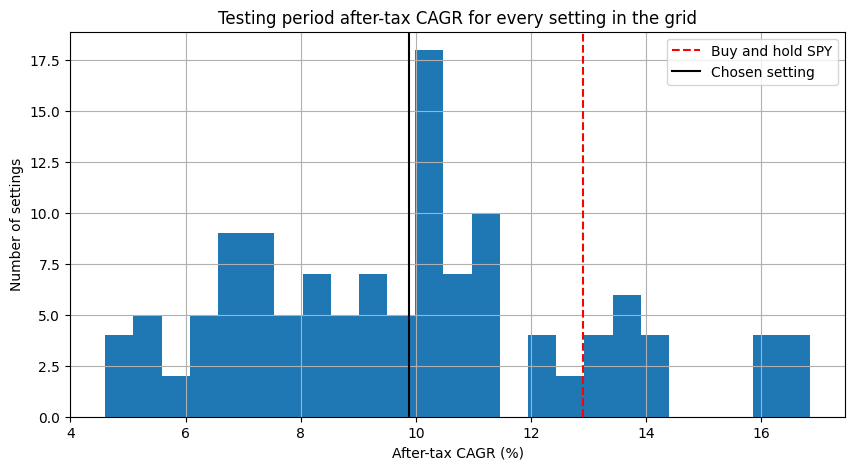

In [12]:
test_results = []

for settings in settings_list:
    bt = run_strategy(data, settings, start=test_start, taxes=True)
    row = dict(settings)
    row["after_tax_cagr"] = after_tax_cagr(bt)
    row["max_drawdown"] = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])["max_drawdown"]
    test_results.append(row)

test_results = pd.DataFrame(test_results)
hold_cagr = table.loc["cagr_after_tax", "Buy and hold SPY"]

print("Settings that beat buy and hold SPY after taxes:",
      int((test_results["after_tax_cagr"] > hold_cagr).sum()), "out of", len(test_results))
print()
print("By up trend position:")
print(test_results.groupby(["up_mode", "up_size"])["after_tax_cagr"].agg(["count", "mean", "min", "max"]))

plt.figure(figsize=(10,5))
plt.hist(test_results["after_tax_cagr"] * 100, bins=25)
plt.axvline(hold_cagr * 100, color="red", linestyle="--", label="Buy and hold SPY")
plt.axvline(table.loc["cagr_after_tax", "Strategy"] * 100, color="black", label="Chosen setting")
plt.title("Testing period after-tax CAGR for every setting in the grid")
plt.xlabel("After-tax CAGR (%)")
plt.ylabel("Number of settings")
plt.legend()
plt.grid(True)
plt.show()

## 7. Walk-forward (2005 to now)

One train/test split depends heavily on where the line is drawn. Instead, every January I score the whole grid from 2000 through the end of the previous year (growth after the taxes paid each year), trade the best setting for the next 12 months, and repeat. Every year from 2005 on gets traded with settings that never saw it. It starts in 2005 so there are at least 5 years to score, since the sector ETFs only go back to December 1998.

The 2005 numbers under Table 3 in the README come from this section.

In [13]:
walk_weights, picks = walk_forward(data, settings_list)

print("Setting picked each year:")
print(picks.to_string())

Setting picked each year:
      sma_months   up_mode  up_size down_mode  beta_window  target_vol
year                                                                  
2005          12  leverage    2.000      cash          252       0.200
2006          12  leverage    2.000      cash          252       0.200
2007          12  leverage    2.000      cash          252       0.200
2008          12  leverage    2.000      cash          252         NaN
2009          12  leverage    2.000      cash          252       0.200
2010          10  leverage    2.000      cash          252       0.200
2011          10  leverage    2.000      cash          252       0.200
2012           8  leverage    2.000      cash          252       0.200
2013           8  leverage    2.000      cash          252       0.200
2014           8  leverage    2.000      cash          252       0.200
2015           8  leverage    2.000      cash          252       0.200
2016           8  leverage    2.000      cash      

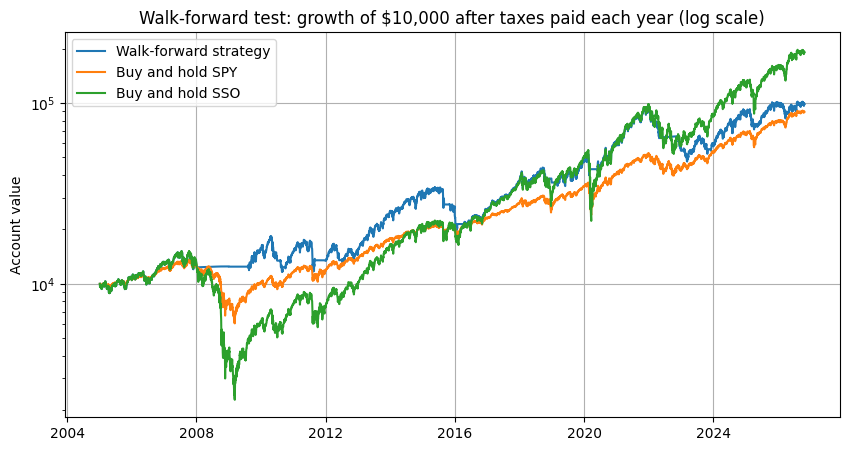

,Walk-forward strategy,Buy and hold SPY,Buy and hold SSO
value_before_tax,"136,102.392","94,966.294","200,264.851"
value_after_tax_sold,"93,493.980","78,879.141","164,634.462"
cagr_after_tax,0.108,0.099,0.137
volatility,0.243,0.189,0.371
sharpe,0.543,0.549,0.510
max_drawdown,-0.484,-0.552,-0.847
beta,0.853,1.000,1.960


In [14]:
wf_start = "2005-01-01"

walk_runs = {
    "Walk-forward strategy": (simulate(data, walk_weights, start=wf_start),
                              simulate(data, walk_weights, start=wf_start, taxes=True)),
    "Buy and hold SPY": (run_fixed(data, {"SPY": 1.0}, start=wf_start),
                         run_fixed(data, {"SPY": 1.0}, start=wf_start, taxes=True)),
    "Buy and hold SSO": (run_fixed(data, {"SSO": 1.0}, start=wf_start),
                         run_fixed(data, {"SSO": 1.0}, start=wf_start, taxes=True)),
}

walk_table = {}
for name, (bt, taxed) in walk_runs.items():
    stats = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])
    walk_table[name] = {
        "value_before_tax": bt["value"].iloc[-1],
        "value_after_tax_sold": taxed.attrs["liquidation_value"],
        "cagr_after_tax": after_tax_cagr(taxed),
        "volatility": stats["volatility"],
        "sharpe": stats["sharpe"],
        "max_drawdown": stats["max_drawdown"],
        "beta": stats["beta"],
    }
walk_table = pd.DataFrame(walk_table)

plt.figure(figsize=(10,5))
for name, (bt, taxed) in walk_runs.items():
    plt.plot(taxed.index, taxed["value"], label=name)
plt.yscale("log")
plt.title("Walk-forward test: growth of $10,000 after taxes paid each year (log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.show()

walk_table

In [15]:
# same signals, different start years
rows = []
for start in ["2005-01-01", "2008-01-01", "2010-01-01", "2015-01-01", "2020-01-01"]:
    walk = simulate(data, walk_weights, start=start, taxes=True)
    hold = run_fixed(data, {"SPY": 1.0}, start=start, taxes=True)
    rows.append({
        "start": start,
        "walk_forward_after_tax_cagr": after_tax_cagr(walk),
        "spy_after_tax_cagr": after_tax_cagr(hold),
        # pre-tax drawdowns so they match the other tables
        "walk_forward_max_drawdown": get_stats(simulate(data, walk_weights, start=start)["strategy_return"], walk["tbill_return"], walk["spy_return"])["max_drawdown"],
        "spy_max_drawdown": get_stats(run_fixed(data, {"SPY": 1.0}, start=start)["strategy_return"], hold["tbill_return"], hold["spy_return"])["max_drawdown"],
    })
by_start = pd.DataFrame(rows).set_index("start")

walk_pre = walk_runs["Walk-forward strategy"][0]
hold_pre_wf = walk_runs["Buy and hold SPY"][0]
walk_yearly = pd.DataFrame({
    "Walk-forward": (1 + walk_pre["strategy_return"]).groupby(walk_pre.index.year).prod() - 1,
    "Buy and hold SPY": (1 + hold_pre_wf["strategy_return"]).groupby(hold_pre_wf.index.year).prod() - 1,
})
walk_yearly = walk_yearly.loc[walk_yearly.index >= 2005]
walk_yearly["Difference"] = walk_yearly["Walk-forward"] - walk_yearly["Buy and hold SPY"]
print(walk_yearly.round(3).T.to_string())
print()
by_start

Date               2005  2006   2007   2008   2009   2010   2011   2012  2013  2014   2015   2016  2017   2018   2019  2020  2021   2022   2023  2024   2025   2026
Walk-forward      0.047 0.248  0.004 -0.003  0.240 -0.029 -0.095  0.111 0.705 0.255 -0.183  0.060 0.444  0.049  0.311 0.308 0.606 -0.396  0.088 0.435  0.157  0.021
Buy and hold SPY  0.053 0.158  0.051 -0.368  0.264  0.151  0.019  0.160 0.323 0.135  0.012  0.120 0.217 -0.046  0.312 0.183 0.287 -0.182  0.262 0.249  0.177  0.137
Difference       -0.006 0.089 -0.048  0.365 -0.024 -0.179 -0.114 -0.049 0.382 0.121 -0.196 -0.060 0.226  0.095 -0.002 0.125 0.318 -0.214 -0.173 0.186 -0.020 -0.116



,walk_forward_after_tax_cagr,spy_after_tax_cagr,walk_forward_max_drawdown,spy_max_drawdown
start,,,,
2005-01-01,0.108,0.099,-0.484,-0.552
2008-01-01,0.113,0.103,-0.484,-0.519
2010-01-01,0.113,0.129,-0.484,-0.337
2015-01-01,0.105,0.123,-0.484,-0.337
2020-01-01,0.108,0.134,-0.484,-0.337


## 8. Does the beta benchmark matter?

SPY contains every sector, so a sector's beta to SPY is partly measured against itself. For example, tech is about 30% of SPY, which inflates its beta. This reruns the walk-forward with each sector measured against the equal weight average of the other 8 instead.

In [16]:
strategy.beta_benchmark = "leave_one_out"
loo_weights, loo_picks = walk_forward(data, settings_list)
loo = simulate(data, loo_weights, start=wf_start, taxes=True)
strategy.beta_benchmark = "spy"

print("Walk-forward after-tax CAGR from 2005, beta vs SPY:", str(round(walk_table.loc["cagr_after_tax", "Walk-forward strategy"] * 100, 2)) + "%")
print("Walk-forward after-tax CAGR from 2005, beta vs the other 8 sectors:", str(round(after_tax_cagr(loo) * 100, 2)) + "%")
print("Years where the picked setting used sectors:", int((loo_picks["up_mode"] == "sectors").sum() + (loo_picks["down_mode"] == "low_beta").sum()))
print()
print("Highest beta sectors right now:")
for benchmark in ["spy", "leave_one_out"]:
    strategy.beta_benchmark = benchmark
    top = get_sector_betas(data, 252).iloc[-1].sort_values(ascending=False)
    print("  vs", benchmark + ":", ", ".join(top.index[:3] + " (" + top.round(2).astype(str)[:3] + ")"))
strategy.beta_benchmark = "spy"

Walk-forward after-tax CAGR from 2005, beta vs SPY: 10.8%
Walk-forward after-tax CAGR from 2005, beta vs the other 8 sectors: 10.31%
Years where the picked setting used sectors: 1

Highest beta sectors right now:
  vs spy: XLK (1.78), XLY (1.16), XLI (0.95)
  vs leave_one_out: XLB (1.39), XLI (1.27), XLY (1.13)


## 9. Monte Carlo (block bootstrap)

2,000 simulated 5-year periods built from random 21 day blocks of the test years (before-tax returns), with the strategy and buy and hold using the same blocks.

The main caveat is that this reshuffles the strategy's actual returns instead of re-running the rules on a new price path. Those returns already include being in T-bills during the real crashes, so it can't show a world where the filter fails, which makes the strategy look more reliable than it is. v3 has a Monte Carlo that re-runs the rules instead.

Chance the strategy has a higher CAGR: 39.6%
Chance the strategy has a higher Sharpe: 16.6%
Chance the strategy has a smaller max drawdown: 8.5%


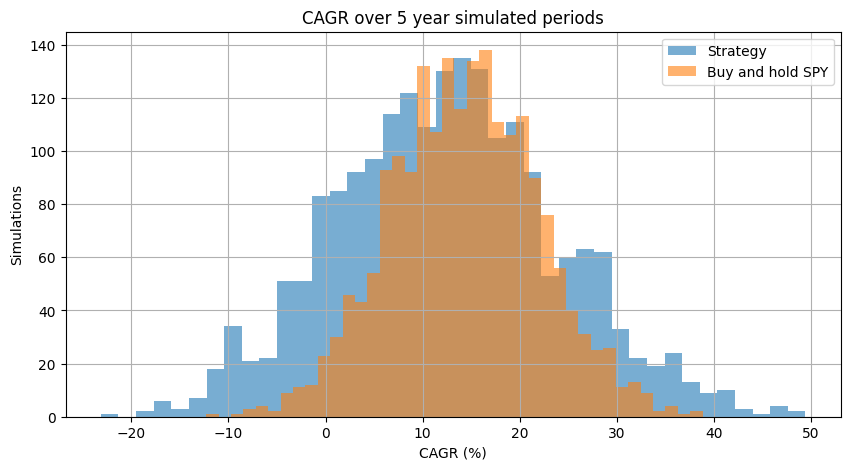

,Strategy CAGR,SPY CAGR,Strategy max DD,SPY max DD
5th percentile,-0.062,0.019,-0.581,-0.403
median,0.125,0.144,-0.357,-0.215
95th percentile,0.318,0.270,-0.224,-0.127


In [17]:
mc = block_bootstrap(strategy_pre["strategy_return"], hold_pre["strategy_return"], strategy_pre["tbill_return"],
                     years=5, block_size=21, sims=2000)

print("Chance the strategy has a higher CAGR:", str(round((mc["strategy_cagr"] > mc["spy_cagr"]).mean() * 100, 1)) + "%")
print("Chance the strategy has a higher Sharpe:", str(round((mc["strategy_sharpe"] > mc["spy_sharpe"]).mean() * 100, 1)) + "%")
print("Chance the strategy has a smaller max drawdown:", str(round((mc["strategy_drawdown"] > mc["spy_drawdown"]).mean() * 100, 1)) + "%")

summary = pd.DataFrame({
    "Strategy CAGR": mc["strategy_cagr"].quantile([0.05, 0.5, 0.95]),
    "SPY CAGR": mc["spy_cagr"].quantile([0.05, 0.5, 0.95]),
    "Strategy max DD": mc["strategy_drawdown"].quantile([0.05, 0.5, 0.95]),
    "SPY max DD": mc["spy_drawdown"].quantile([0.05, 0.5, 0.95]),
})
summary.index = ["5th percentile", "median", "95th percentile"]

plt.figure(figsize=(10,5))
plt.hist(mc["strategy_cagr"] * 100, bins=40, alpha=0.6, label="Strategy")
plt.hist(mc["spy_cagr"] * 100, bins=40, alpha=0.6, label="Buy and hold SPY")
plt.title("CAGR over 5 year simulated periods")
plt.xlabel("CAGR (%)")
plt.ylabel("Simulations")
plt.legend()
plt.grid(True)
plt.show()

summary

## 10. Full history (just for context)

The chosen settings from 2000 to now, with taxes. 2000-2009 is in-sample here, so this is only to see how the rules behaved in 2000-2002 and 2008.

Strategy after tax, sold today: $120,394
Buy and hold SPY after tax, sold today: $69,793


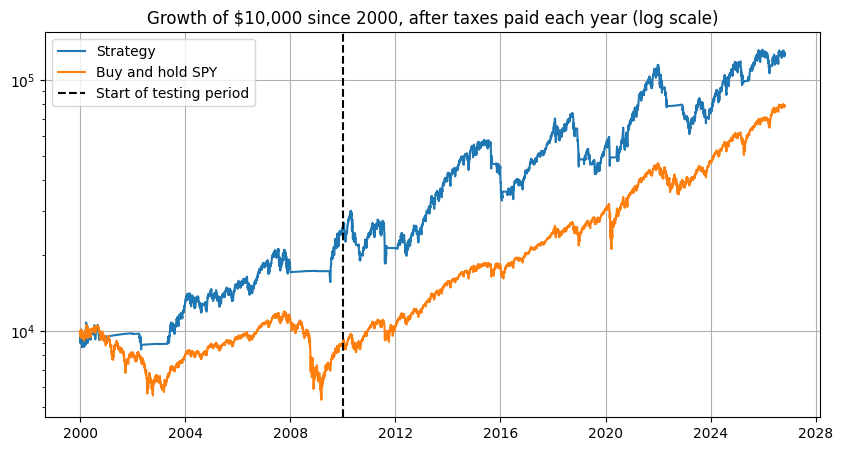

In [18]:
full = run_strategy(data, s, start=train_start, taxes=True)
full_hold = run_fixed(data, {"SPY": 1.0}, start=train_start, taxes=True)

print("Strategy after tax, sold today: $" + format(round(full.attrs["liquidation_value"]), ","))
print("Buy and hold SPY after tax, sold today: $" + format(round(full_hold.attrs["liquidation_value"]), ","))

plt.figure(figsize=(10,5))
plt.plot(full.index, full["value"], label="Strategy")
plt.plot(full_hold.index, full_hold["value"], label="Buy and hold SPY")
plt.axvline(pd.Timestamp(test_start), color="black", linestyle="--", label="Start of testing period")
plt.yscale("log")
plt.title("Growth of $10,000 since 2000, after taxes paid each year (log scale)")
plt.legend()
plt.grid(True)
plt.show()

## Findings

(Data through October 29, 2026. Next-day trades, wash sale rule, SSO payouts taxed as ordinary income.)

The tradable version of the idea didn't work. When I split months by whether SPY beat T-bills that month, high beta sectors did better in up months (t = 3.9 from 2010 on) and worse in down months (t = -4.9), which matches the papers. However, that split uses next month's return, and as I said above, it mostly comes out that way automatically. When I split by the trend signal known at the start of the month instead, the slope was close to zero (t = 0.06 in uptrends from 2010 on, t = -0.21 in training). Knowing the trend ahead of time didn't say anything about whether high beta sectors would do better. This is also why the walk-forward never picked the high beta sectors for uptrends. It picked 2x every single year, and T-bills for downtrends in every year except 2024-2026, when it switched to the low beta sectors. So in practice the strategy turned into "2x in uptrends, T-bills in downtrends."

With the fixed split, the 2000-2009 pick made 9.9% a year after tax from 2010 on vs 12.9% for buy and hold SPY, with a worse max drawdown (-45% vs -34%). Only 22 of the 126 settings beat SPY after tax, and those were mostly the 2x ones.

The walk-forward did beat SPY after taxes, but barely. From 2005, $10,000 became about $93,500 vs $78,900 for SPY (10.8% vs 9.9% a year), with a smaller max drawdown (-48% vs -55%), although the Sharpe ratio was about the same (0.54 vs 0.55). Holding SSO alone made more (13.7% a year), but with an -85% drawdown.

Almost all of that win comes from 2008, when it was in T-bills (-0.3%) while SPY lost 37%. Starting the clock in 2010, 2015 or 2020, it trails SPY after tax (11.3% vs 12.9%, 10.5% vs 12.3%, 10.8% vs 13.4%).

Measuring sector betas against the other 8 sectors instead of SPY gave 10.3% instead of 10.8% from 2005, so that choice didn't change much.

v2 beat SPY after taxes only because it sat out 2008. I wouldn't call it a reliable way to beat buy and hold.

## Limitations

- Since SSO resets to 2x every day, it can lose money in a choppy market even when SPY ends up flat. In addition, if SPY ever fell 50% in one day, SSO would go to zero. Checking once a month means a crash inside a month hits at full leverage.
- SSO before June 2006 is rebuilt from SPY, not real prices.
- Trades fill at the next day's close. A real order would probably go in near the close or at the next open.
- 5 bps per trade is an estimate. These ETFs are very liquid, so it should be on the safe side.
- Federal tax only at today's rates, no state tax (Maryland would add more for every strategy here). Taxes come out in December instead of April.
- The wash sale rule is simplified: a disallowed loss gets added back in the year the replacement shares are bought, and the holding period doesn't carry over.
- Only the 9 original sector ETFs, since real estate (XLRE) and communication services (XLC) only started in 2015 and 2018.
- 26 years of data only has a few real bear markets, so a handful of events drive most of this.

## Environment

The cell below prints the Python and package versions I used for the last run. It also prints the last date in each data file and a short SHA-256 hash of the file. Yahoo Finance sometimes revises old prices, so if a hash here doesn't match yours, the two downloads aren't the same.

In [19]:
import sys
import hashlib
from importlib.metadata import version

print("Python", sys.version.split()[0])
for package in ["pandas", "numpy", "matplotlib", "yfinance"]:
    print(package, version(package))
print()

for name in ["SPY", "SSO", "XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY", "dtb3"]:
    path = "../data/" + name + ".csv"
    with open(path, "rb") as f:
        sha = hashlib.sha256(f.read()).hexdigest()[:12]
    last_row = pd.read_csv(path).iloc[-1, 0]
    print(name.ljust(6), "last row", last_row, " sha256", sha)

Python 3.9.6
pandas 2.3.3
numpy 2.0.2
matplotlib 3.9.4
yfinance 1.2.0

SPY    last row 2026-10-29  sha256 6527e60d275b
SSO    last row 2026-10-29  sha256 64dd0a614435
XLB    last row 2026-10-29  sha256 66efd5fce967
XLE    last row 2026-10-29  sha256 17f55e935de0
XLF    last row 2026-10-29  sha256 2da6af6a4cf1
XLI    last row 2026-10-29  sha256 e3fdf0d12640
XLK    last row 2026-10-29  sha256 1a8b959f292a
XLP    last row 2026-10-29  sha256 be32cd46419f
XLU    last row 2026-10-29  sha256 76f4d8cf0f5f
XLV    last row 2026-10-29  sha256 03c6b3ac6a3e
XLY    last row 2026-10-29  sha256 ee3eb1718dff
dtb3   last row 2026-10-28  sha256 ac9d2b8590e6
